# Оптический поток: FlowNetS и FlowNetC

Разберём FlowNetS на PyTorch и сравним её с готовой FlowNetC и Farnebäck. Обе сети используют предобученные веса: здесь выполняется предсказание, обучение не запускается.

In [1]:
# Выводим графики прямо в notebook.
%matplotlib inline

from pathlib import Path
import sys

# Работает при запуске из корня репозитория и из папки этого notebook.
PROJECT = Path("flownet_lesson")
if not PROJECT.is_dir():
    PROJECT = Path("lessons/lesson_02/flownet_lesson")
if not PROJECT.is_dir():
    PROJECT = Path(".")
sys.path.insert(0, str(PROJECT.resolve()))

import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
import torch
from torch import nn
import torch.nn.functional as F
from IPython.display import Video, display

from inference import checkpoint, load_model, prepare_pair, restore_flow
from flow_utils import farneback, flow_rgb, flow_arrows, read_pair

# Пути отсчитываются от папки notebook.
DATA = PROJECT / "data"
OUTPUTS = PROJECT / "outputs"

## FlowNetS: два кадра → признаки → поле движения

Два RGB-кадра соединяем в 6 каналов. Encoder уменьшает пространственную сетку и извлекает признаки. Decoder повышает разрешение, соединяя признаки encoder, поднятые признаки decoder и промежуточный поток.

`Conv2d` — свёртка, `stride=2` уменьшает сетку; `ConvTranspose2d` повышает разрешение обучаемым преобразованием; `torch.cat(..., dim=1)` соединяет каналы. `predict_flow` выдаёт два канала `(u, v)` без ограничивающей активации. Финальный `flow2` имеет сетку примерно H/4 × W/4.

Ниже — собственная запись архитектуры FlowNetS, совместимая с исходными весами. FlowNetC берём готовой из FlowNetPytorch: она отдельно извлекает признаки двух кадров общими слоями и сопоставляет их через correlation. Её архитектуру здесь не реализуем.

In [2]:
def conv(in_channels, out_channels, kernel_size=3, stride=1):
    """Свёртка и LeakyReLU; stride=2 уменьшает пространственное разрешение."""
    return nn.Sequential(
        nn.Conv2d(
            in_channels, out_channels,  # Число входных и выходных признаков.
            kernel_size=kernel_size,   # Размер обучаемого пространственного фильтра.
            stride=stride,             # Шаг фильтра по изображению.
            padding=kernel_size // 2,  # При stride=1 сохраняем высоту и ширину.
        ),
        nn.LeakyReLU(negative_slope=0.1, inplace=True),  # Отрицательные значения умножаем на 0.1.
    )


def deconv(in_channels, out_channels):
    """Обучаемое повышение разрешения вдвое."""
    return nn.Sequential(
        nn.ConvTranspose2d(
            in_channels, out_channels,
            kernel_size=4, stride=2, padding=1,  # Размер выхода ровно вдвое больше.
            bias=False,  # Соответствует сохранённым весам модели.
        ),
        nn.LeakyReLU(negative_slope=0.1, inplace=True),
    )


def predict_flow(in_channels):
    """Из признаков получаем два канала смещения: u и v."""
    # Без активации: компоненты потока могут быть отрицательными.
    return nn.Conv2d(in_channels, 2, kernel_size=3, padding=1, bias=False)


def upsample_flow():
    """Увеличить сетку промежуточного потока обучаемым слоем."""
    return nn.ConvTranspose2d(2, 2, kernel_size=4, stride=2, padding=1, bias=False)


def crop(tensor, reference):
    """Подогнать высоту и ширину перед соединением каналов."""
    # На нечётных размерах encoder и decoder могут различаться на один пиксель.
    return tensor[:, :, :reference.shape[2], :reference.shape[3]]


class SimpleFlowNetS(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder получает два RGB-кадра, соединённых в 6 каналов.
        self.conv1 = conv(6, 64, kernel_size=7, stride=2)
        self.conv2 = conv(64, 128, kernel_size=5, stride=2)
        self.conv3 = conv(128, 256, kernel_size=5, stride=2)
        self.conv3_1 = conv(256, 256)
        self.conv4 = conv(256, 512, stride=2)
        self.conv4_1 = conv(512, 512)
        self.conv5 = conv(512, 512, stride=2)
        self.conv5_1 = conv(512, 512)
        self.conv6 = conv(512, 1024, stride=2)
        self.conv6_1 = conv(1024, 1024)

        # Decoder соединяет skip-признаки, поднятые признаки и два канала потока.
        self.deconv5 = deconv(1024, 512)
        self.deconv4 = deconv(1026, 256)  # 512 + 512 + 2 на предыдущем уровне.
        self.deconv3 = deconv(770, 128)   # 512 + 256 + 2.
        self.deconv2 = deconv(386, 64)    # 256 + 128 + 2.

        # Предсказания на пяти масштабах; flow2 имеет сетку примерно H/4 × W/4.
        self.predict_flow6 = predict_flow(1024)
        self.predict_flow5 = predict_flow(1026)
        self.predict_flow4 = predict_flow(770)
        self.predict_flow3 = predict_flow(386)
        self.predict_flow2 = predict_flow(194)  # 128 + 64 + 2.

        self.upsampled_flow6_to_5 = upsample_flow()
        self.upsampled_flow5_to_4 = upsample_flow()
        self.upsampled_flow4_to_3 = upsample_flow()
        self.upsampled_flow3_to_2 = upsample_flow()

    def forward(self, pair):
        # Сохраняем признаки encoder для skip connections.
        conv2 = self.conv2(self.conv1(pair))
        conv3 = self.conv3_1(self.conv3(conv2))
        conv4 = self.conv4_1(self.conv4(conv3))
        conv5 = self.conv5_1(self.conv5(conv4))
        conv6 = self.conv6_1(self.conv6(conv5))

        # Первое предсказание строится на самой грубой сетке H/64 × W/64.
        flow6 = self.predict_flow6(conv6)
        features5 = crop(self.deconv5(conv6), conv5)
        flow6_up = crop(self.upsampled_flow6_to_5(flow6), conv5)
        concat5 = torch.cat([conv5, features5, flow6_up], dim=1)  # Соединяем каналы.
        flow5 = self.predict_flow5(concat5)

        # Каждый следующий шаг использует encoder-признаки своего масштаба.
        features4 = crop(self.deconv4(concat5), conv4)
        flow5_up = crop(self.upsampled_flow5_to_4(flow5), conv4)
        concat4 = torch.cat([conv4, features4, flow5_up], dim=1)
        flow4 = self.predict_flow4(concat4)

        features3 = crop(self.deconv3(concat4), conv3)
        flow4_up = crop(self.upsampled_flow4_to_3(flow4), conv3)
        concat3 = torch.cat([conv3, features3, flow4_up], dim=1)
        flow3 = self.predict_flow3(concat3)

        features2 = crop(self.deconv2(concat3), conv2)
        flow3_up = crop(self.upsampled_flow3_to_2(flow3), conv2)
        concat2 = torch.cat([conv2, features2, flow3_up], dim=1)
        flow2 = self.predict_flow2(concat2)

        # Несколько выходов нужны для multiscale loss; на инференсе берём flow2.
        if self.training:
            return flow2, flow3, flow4, flow5, flow6
        return flow2

## Предобученные веса

`state_dict` хранит обученные параметры, но не выполняет архитектуру. Создаём модель, загружаем все параметры и переводим её в `eval()`. В следующих примерах используется именно класс `SimpleFlowNetS`, определённый выше.

Если весов нет, выполните `python fetch_assets.py`. Источники и SHA-256 сохранены в `assets.json`; код исходной реализации и MIT-лицензия — в `vendor/`.

In [3]:
# Загружаем FlowNetS в класс из предыдущей ячейки.
weights = checkpoint("flownets")
model_s = SimpleFlowNetS()
model_s.load_state_dict(weights["state_dict"], strict=True)  # Все имена и размеры должны совпасть.
model_s.eval()  # Режим предсказания; граф градиентов отключается отдельно.
div_flow_s = float(weights.get("div_flow", 20))
del weights  # Дополнительная копия весов больше не нужна.

# FlowNetC создаётся по сохранённой реализации; correlation заменён чистым PyTorch.
model_c, div_flow_c = load_model("flownetc")

# Модели загружены один раз и будут передаваться в predict явно.
print("FlowNetS:", sum(parameter.numel() for parameter in model_s.parameters()), "параметров")
print("FlowNetC:", sum(parameter.numel() for parameter in model_c.parameters()), "параметров")
print("Масштаб векторов:", div_flow_s, div_flow_c)

FlowNetS: 38675536 параметров
FlowNetC: 39174320 параметров
Масштаб векторов: 20.0 20.0


## Предсказание на паре кадров

`prepare_pair` переводит RGB в `[0, 1]`, вычитает средние `[0.411, 0.432, 0.450]` и дополняет кадры справа/снизу до кратности 64. Исходную область не растягиваем. Например, пара 180×320 превращается в тензор `(1, 6, 192, 320)`.

`restore_flow` интерполирует сетку результата, умножает векторы на `div_flow=20` и убирает padding. Эти веса предсказывают смещения в пикселях полного входа, делённых на 20: дополнительно умножать на 4 не нужно.

Результат — `(H, W, 2)`: `flow[y, x] = (u, v)`, вправо и вниз положительны. Единицы — пиксели за интервал между выбранными кадрами.

In [4]:
@torch.inference_mode()  # Отключаем граф градиентов для предсказания.
def predict(model, first, second, div_flow=20):
    pair = prepare_pair(first, second)  # RGB → нормировка → 6 каналов → padding.
    raw_flow = model(pair)             # Прямой проход с обученными весами.
    return restore_flow(raw_flow, pair.shape[-2:], first.shape[:2], div_flow)


first, second = read_pair(DATA / "bowling.mp4", frame=30, gap=5)
flow = predict(model_s, first, second, div_flow_s)
print("Поле:", flow.shape, flow.dtype)  # (180, 320, 2), float32.
print("Вектор в центре (u, v):", flow[90, 160])

Поле: (180, 320, 2) float32
Вектор в центре (u, v): [-0.33540663 -0.81393594]


## Видео

Для одной пары сравним Farnebäck, FlowNetS и FlowNetC. Цветовой тон задаёт направление, яркость — модуль. Шкала общая: каждый кадр не нормируется на свой максимум. В режиме стрелок длины остаются в масштабе 1:1; показана лишь часть векторов для читаемости.

`gap` измеряется в исходных кадрах. Истинного потока здесь нет, поэтому по этим видео EPE не вычисляем. Поток включает движение камеры и не является сегментацией объектов.

In [5]:
def compare_pair(first, second, scale=8, mode="color"):
    """Посчитать три поля на одинаковой паре RGB-кадров."""
    previous = cv2.cvtColor(first, cv2.COLOR_RGB2GRAY)  # Farnebäck использует один канал.
    current = cv2.cvtColor(second, cv2.COLOR_RGB2GRAY)
    flow_cv = farneback(previous, current)
    flow_s = predict(model_s, first, second, div_flow_s)
    flow_c = predict(model_c, first, second, div_flow_c)
    results = {"Farneback": flow_cv, "FlowNetS": flow_s, "FlowNetC": flow_c}

    figure, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes[0, 0].imshow(first)
    axes[0, 0].set_title("Первый кадр")
    for axis, (name, flow) in zip(axes.flat[1:], results.items()):
        if mode == "color":
            image = flow_rgb(flow, max_motion=scale)  # Одна верхняя граница для всех методов.
        else:
            image = flow_arrows(first, flow, step=12)  # Прореживаем только отрисовку.
        axis.imshow(image)
        axis.set_title(name)
    for axis in axes.flat:
        axis.axis("off")
    figure.suptitle(f"Шкала цвета: 0–{scale} px за пару")
    plt.tight_layout()
    plt.show()
    return results


def video_demo(clip="bowling", frame=30, gap=5, scale=8, mode="color"):
    # read_pair уже переводит BGR из OpenCV в RGB, как требуется этим весам.
    first, second = read_pair(DATA / f"{clip}.mp4", frame, gap)
    compare_pair(first, second, scale, mode)


widgets.interact(
    video_demo,
    clip=["bowling", "archery"],
    frame=widgets.IntSlider(value=30, min=0, max=60, continuous_update=False),
    gap=widgets.IntSlider(value=5, min=1, max=15, continuous_update=False),
    scale=widgets.SelectionSlider(options=[2, 4, 8, 16, 32], value=8, continuous_update=False),
    mode=[("Цвет", "color"), ("Стрелки 1:1", "arrows")],
);

interactive(children=(Dropdown(description='clip', options=('bowling', 'archery'), value='bowling'), IntSlider…

## Проверка на известном переносе

Перенесём один кадр на `(4, 2)` пикселя. Теперь истинный поток известен в центральной области. EPE — длина разности найденного и истинного векторов; меньше — точнее. Сравниваем методы на одинаковых пикселях.

Такой пример не заменяет проверку на наборе данных. Предобученная сеть может уступить Farnebäck на конкретной паре и не обязана выдавать точный ноль на одинаковых кадрах.

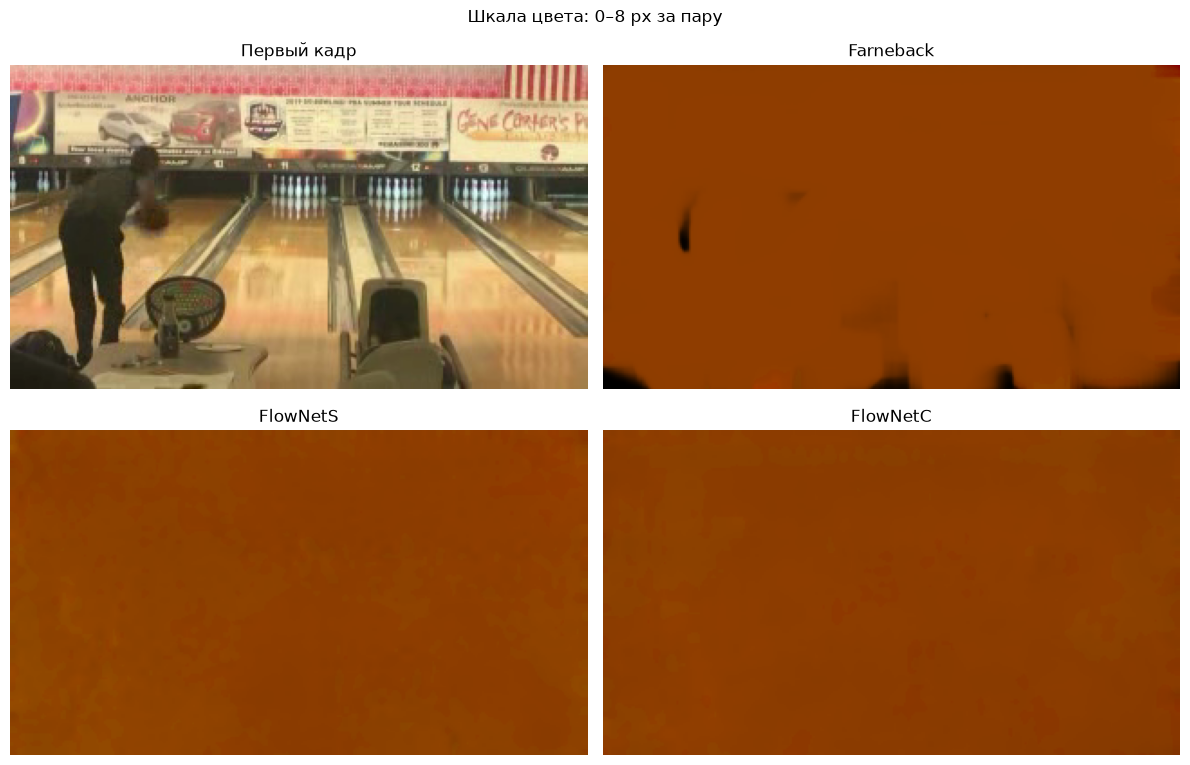

Farneback: медиана EPE 0.000; p90 0.017 px
FlowNetS: медиана EPE 0.126; p90 0.206 px
FlowNetC: медиана EPE 0.101; p90 0.158 px


In [6]:
dx, dy = 4, 2  # Известный перенос вправо и вниз, в пикселях.
first = read_pair(DATA / "bowling.mp4", frame=10)[0]
height, width = first.shape[:2]
transform = np.float32([[1, 0, dx], [0, 1, dy]])  # Матрица переноса 2×3.
second = cv2.warpAffine(
    first, transform, (width, height),  # Размер выхода: ширина, высота.
    borderMode=cv2.BORDER_REFLECT_101,  # Открывшиеся края дополняем отражением.
)
results = compare_pair(first, second, scale=8)
for name, flow in results.items():
    # Одинаковая центральная область: отражённые края исключаем.
    error = np.linalg.norm(flow[32:-32, 32:-32] - [dx, dy], axis=-1)
    print(f"{name}: медиана EPE {np.median(error):.3f}; "
          f"p90 {np.percentile(error, 90):.3f} px")

## Видеосравнения

`run_demo.py` сохраняет исходный кадр и три цветовых поля в четырёх панелях. Обрабатывается каждый третий кадр; fps уменьшается с 15 до 5 для сохранения примерно исходного темпа. `gap` задаёт интервал между исходными кадрами, а `stride` — шаг выбора первых кадров пар.

In [7]:
for path in sorted(OUTPUTS.glob("*_flownet_gap5.mp4")):
    # embed=True сохраняет видео в выводе notebook; width — ширина плеера в px.
    display(Video(str(path), embed=True, width=640))

## Источники

- [FlowNet 2015](https://arxiv.org/abs/1504.06852).
- [FlowNetPytorch и веса](https://github.com/ClementPinard/FlowNetPytorch).
- [Предобработка и масштаб в исходной реализации](https://github.com/ClementPinard/FlowNetPytorch/blob/d5f3292a738209d5f3ea450cf714265034fd033a/run_inference.py).
- [Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) и [ConvTranspose2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html).

Реализация FlowNetS совместима с исходными весами. Проверка в `validate.py` сравнивает выходы с сохранённой реализацией и проверяет единицы потока. Подготовка кадров находится в `inference.py`. CPU-адаптер correlation для готовой FlowNetC оставлен в `correlation.py` как техническая зависимость; в разбор он не входит.